# 03b · Vacancy outlook 2030 by neighborhood (run on LinuxONE)

**Question:** which neighborhoods (AGEB) will be among the most vacant of the city ten years from now?

**Why a ranking and not a %:** Juárez had 111,103 vacant homes in 2010 (right after the violence crisis) and 55,595 in 2020; the median neighborhood went from 20.8% to 10.1% vacant. A model that predicts the % would learn that recovery, and nobody knows if 2020 to 2030 will repeat it. So the target is each neighborhood's **position within the city** (percentile of % vacant), which does not depend on the city-wide level.

**Method:**
1. Census 2010 and 2020 by AGEB, same variables. Census features are used as **within-year percentiles** only, so changes like internet adoption between decades do not shift the scale (raw values plus ranks made the linear model's reasons unstable; electricity is dropped because it is near 100% everywhere).
2. Train on **2010 features → 2020 vacancy rank**; validate with spatial folds (groups of nearby neighborhoods), repeated with 5 different groupings.
3. The model must beat **persistence** (2020 rank = 2010 rank) to be used.
4. Apply the chosen model to **2020 features → 2030 outlook**.

**Limits:** one decade of history that includes a crisis and its recovery; about 550 neighborhoods; maquila locations are from 2022 for both periods. The 2030 outlook is a scenario if the 2010 to 2020 pattern continues, not a certainty.

In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import xgboost as xgb
except Exception as e:
    xgb = None
    print("XGBoost skipped:", type(e).__name__)
print(platform.machine(), "| Python", platform.python_version())
MIN_HOMES = 50
TOP = 0.10

arm64 | Python 3.14.7


## 1. Panel 2010 and 2020 by AGEB

In [2]:
def census_year(path):
    c = pd.read_csv(path, dtype=str)
    c.columns = c.columns.str.lower()
    if "nom_loc" in c:
        c = c[c.nom_loc == "Total AGEB urbana"]
    c = c.copy()
    c["cvegeo"] = c.entidad + c.mun + c["loc"] + c.ageb
    masked = c.vivpar_des == "*"
    num = ["pobtot", "p_12ymas", "pob0_14", "pob65_mas", "pder_ss", "pea", "graproes", "prom_ocup", "tvivpar",
           "tvivparhab", "vivpar_des", "vph_inter", "vph_autom", "vph_pisoti", "vph_c_elec", "vph_aguadv",
           "vph_drenaj", "vph_pc", "vph_cel", "vph_1cuart"]
    c[num] = c[num].apply(pd.to_numeric, errors="coerce")
    c["vivpar_des"] = np.where(masked, 1.5, c.vivpar_des)  # INEGI masks 1 or 2 as '*'
    c = c[c.tvivpar >= MIN_HOMES]
    f = pd.DataFrame(index=c.cvegeo.values)
    f["vacancy_pct"] = (c.vivpar_des / c.tvivpar * 100).values
    f["log_homes"] = np.log(c.tvivpar.values)
    f["avg_occupants"] = c.prom_ocup.values
    f["schooling_years"] = c.graproes.values
    for col, den in [("pob0_14", "pobtot"), ("pob65_mas", "pobtot"), ("pder_ss", "pobtot"), ("pea", "p_12ymas")]:
        f[f"pct_{col}"] = (c[col] / c[den] * 100).values
    for col in ["vph_inter", "vph_autom", "vph_pisoti", "vph_c_elec", "vph_aguadv", "vph_drenaj", "vph_pc", "vph_cel", "vph_1cuart"]:
        f[f"pct_{col}"] = (c[col] / c.tvivparhab * 100).values
    return f

y2010 = census_year("../data/raw/juarez_censo2010_ageb.csv")
y2020 = census_year("../data/raw/juarez_censo2020_ageb_manzana.csv")
static = pd.read_csv("../data/ageb_features.csv", dtype={"CVEGEO": str}).set_index("CVEGEO")
STATIC = ["km_center", "km_maquila", "maquilas_3km", "km_brt", "km_health", "area_km2"]
CENSUS = [c for c in y2010.columns]

def relative(f):
    # within-year percentiles: comparable across decades
    return f.rank(pct=True).add_suffix("_rank")

RANKED = [c for c in CENSUS if c != "pct_vph_c_elec"]

def features(f):
    return relative(f[RANKED]).join(static[STATIC], how="inner")

pairs = y2010.index.intersection(y2020.index).intersection(static.index)
X = features(y2010.loc[pairs])
target_rank = y2020.loc[pairs, "vacancy_pct"].rank(pct=True)
is_top = target_rank >= 1 - TOP  # the most vacant 10% of neighborhoods in 2020
print(len(pairs), "neighborhoods in both censuses |", X.shape[1], "features")
print(f"city median vacancy: 2010 {y2010.vacancy_pct.median():.1f}% -> 2020 {y2020.vacancy_pct.median():.1f}%")

546 neighborhoods in both censuses | 22 features
city median vacancy: 2010 20.9% -> 2020 10.3%


## 2. Does 2010 anticipate 2020?
Spatial folds: neighborhoods are grouped into 30 geographic clusters, and whole clusters are held out, so nearby neighborhoods cannot leak into each other. Repeated with 5 different clusterings.

In [3]:
def imputed(model, scale=False):
    return make_pipeline(*([SimpleImputer(strategy="median")] + ([StandardScaler()] if scale else []) + [model]))

CANDIDATES = {
    "Persistence (2020 rank = 2010 rank)": (None, "yes"),
    "Ridge": (lambda: imputed(RidgeCV(alphas=np.logspace(-2, 3, 12)), scale=True), "yes"),
    "Random Forest": (lambda: imputed(RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=0)), "partial"),
}
if xgb is not None:
    CANDIDATES["XGBoost (shallow)"] = (lambda: xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                                  min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                                                                  reg_lambda=5, n_jobs=-1, random_state=0), "yes")
coords = static.loc[pairs, ["lon", "lat"]].to_numpy()
y = target_rank.to_numpy()
rows = []
for seed in range(5):
    groups = KMeans(30, n_init=10, random_state=seed).fit_predict(coords)
    for fold, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups)):
        for name, (make, _) in CANDIDATES.items():
            if make is None:
                pred = X.iloc[te]["vacancy_pct_rank"].to_numpy()
            else:
                pred = make().fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
            flagged = pred >= np.quantile(pred, 1 - TOP)
            rows.append(dict(model=name, seed=seed, fold=fold, hit_rate_top10=is_top.to_numpy()[te][flagged].mean(),
                             spearman=spearmanr(pred, y[te])[0]))
cv = pd.DataFrame(rows)
table = cv.groupby("model").agg(hit_rate_top10=("hit_rate_top10", "mean"), hit_rate_std=("hit_rate_top10", "std"),
                                spearman=("spearman", "mean")).sort_values("hit_rate_top10", ascending=False)
table["explains_each_area"] = [CANDIDATES[m][1] for m in table.index]
print("random flagging would give a hit rate of", TOP)
table.round(3)

random flagging would give a hit rate of 0.1


,hit_rate_top10,hit_rate_std,spearman,explains_each_area
model,,,,
Random Forest,0.465,0.385,0.666,partial
XGBoost (shallow),0.436,0.341,0.656,yes
Ridge,0.430,0.302,0.645,yes
Persistence (2020 rank = 2010 rank),0.321,0.188,0.475,yes


## 3. Decision
A model is only used if its mean hit rate beats persistence. Among those, the best wins; models within one standard deviation of the best tie, and the tie goes to the one that explains each neighborhood, then the simplest (Ridge before XGBoost).

In [4]:
persist = table.loc["Persistence (2020 rank = 2010 rank)", "hit_rate_top10"]
models = table.drop(index="Persistence (2020 rank = 2010 rank)")
beats = models[models.hit_rate_top10 > persist]
if beats.empty:
    winner = None
    print(f"No model beats persistence ({persist:.3f}). Outlook 2030 = current 2020 ranking (vacancy is persistent).")
else:
    best = beats.iloc[0]
    tied = beats[beats.hit_rate_top10 >= best.hit_rate_top10 - best.hit_rate_std].copy()
    order = {"Ridge": 0, "XGBoost (shallow)": 1, "Random Forest": 2}
    tied["explain"] = tied.explains_each_area.map({"yes": 0, "partial": 1})
    tied["simplicity"] = [order.get(m, 9) for m in tied.index]
    winner = tied.sort_values(["explain", "simplicity"]).index[0]
    print("Beat persistence:", list(beats.index), "| tied with best:", list(tied.index))
    print(f"Winner: {winner} (hit rate {table.loc[winner, 'hit_rate_top10']:.3f} vs persistence {persist:.3f})")

Beat persistence: ['Random Forest', 'XGBoost (shallow)', 'Ridge'] | tied with best: ['Random Forest', 'XGBoost (shallow)', 'Ridge']
Winner: Ridge (hit rate 0.430 vs persistence 0.321)


## 4. Outlook 2030
The chosen model is trained on all 2010 to 2020 pairs and applied to 2020 features. Output is a position within the city (0 = least vacant, 1 = most vacant), not a %.

In [5]:
X2020 = features(y2020)
current = y2020.loc[X2020.index, "vacancy_pct"].rank(pct=True)
if winner is None:
    outlook = current.copy()
    contrib = None
else:
    model = CANDIDATES[winner][0]().fit(X, y)
    outlook = pd.Series(model.predict(X2020), index=X2020.index).rank(pct=True)
    if winner.startswith("XGBoost"):
        c = model.get_booster().predict(xgb.DMatrix(X2020), pred_contribs=True)[:, :-1]
        contrib = pd.DataFrame(c, index=X2020.index, columns=X2020.columns)
    elif winner == "Ridge":
        pipe = model
        z = pipe[:-1].transform(X2020)
        contrib = pd.DataFrame(z * pipe[-1].coef_, index=X2020.index, columns=X2020.columns)
    else:
        contrib = None

out = pd.DataFrame({"vacancy_pct_2020": y2020.loc[X2020.index, "vacancy_pct"], "rank_2020": current, "rank_2030_outlook": outlook})
out["change"] = out.rank_2030_outlook - out.rank_2020
out["outlook"] = np.select([out.rank_2030_outlook >= 1 - TOP, out.change >= 0.20, out.change <= -0.20],
                           ["top 10% most vacant", "moving up", "moving down"], "about the same")
if contrib is not None:
    LABELS = {"vacancy_pct_rank": "vacancy now", "log_homes_rank": "number of homes", "avg_occupants_rank": "occupants per home",
              "schooling_years_rank": "schooling", "pct_pob0_14_rank": "% children", "pct_pob65_mas_rank": "% adults 65+",
              "pct_pder_ss_rank": "% with health insurance", "pct_pea_rank": "% economically active",
              "pct_vph_inter_rank": "% homes with internet", "pct_vph_autom_rank": "% homes with car",
              "pct_vph_pisoti_rank": "% dirt floor", "pct_vph_aguadv_rank": "% piped water", "pct_vph_drenaj_rank": "% drainage",
              "pct_vph_pc_rank": "% homes with computer", "pct_vph_cel_rank": "% homes with cell phone",
              "pct_vph_1cuart_rank": "% one-room homes", "km_center": "km to center", "km_maquila": "km to maquila",
              "maquilas_3km": "maquilas within 3 km", "km_brt": "km to BRT", "km_health": "km to health unit", "area_km2": "area"}

    def why(i, n=3):
        top = contrib.loc[i].sort_values(ascending=False).head(n)
        # a positive push can come from a high or a low value; say which
        side = lambda f: "high" if X2020.at[i, f] >= X2020[f].median() else "low"
        return "; ".join(f"{side(f)} {LABELS.get(f, f)} (+{v:.2f})" for f, v in top.items() if v > 0)
    out["main_drivers"] = [why(i) for i in out.index]
out = out.join(static[["lon", "lat"]])
print(out.outlook.value_counts().to_string())
out.sort_values("change", ascending=False).head(10).round(3)

outlook
about the same         385
moving down             69
top 10% most vacant     57
moving up               56


,vacancy_pct_2020,rank_2020,rank_2030_outlook,change,outlook,main_drivers,lon,lat
0803700014118,5.576,0.111,0.614,0.503,moving up,low maquilas within 3 km (+0.06); low % with h...,-106.518,31.730
0803700015366,1.923,0.002,0.441,0.439,moving up,low maquilas within 3 km (+0.06); low number o...,-106.530,31.774
080370001457A,4.840,0.056,0.483,0.427,moving up,low % homes with cell phone (+0.05); low km to...,-106.481,31.671
0803700011594,6.080,0.146,0.570,0.423,moving up,low maquilas within 3 km (+0.06); low % with h...,-106.503,31.714
0803700018144,5.556,0.109,0.533,0.423,moving up,high km to BRT (+0.15); high km to health unit...,-106.570,31.615
0803700014226,7.069,0.222,0.644,0.422,moving up,low maquilas within 3 km (+0.06); low % with h...,-106.514,31.715
0803700014175,6.180,0.152,0.557,0.406,moving up,low maquilas within 3 km (+0.06); low % with h...,-106.516,31.723
0803700014137,7.816,0.287,0.691,0.404,moving up,low occupants per home (+0.06); low maquilas w...,-106.513,31.727
0803700014885,5.590,0.115,0.492,0.377,moving up,low maquilas within 3 km (+0.04); low number o...,-106.488,31.676
0803700015351,3.837,0.021,0.388,0.367,moving up,low occupants per home (+0.08); high % adults ...,-106.414,31.735


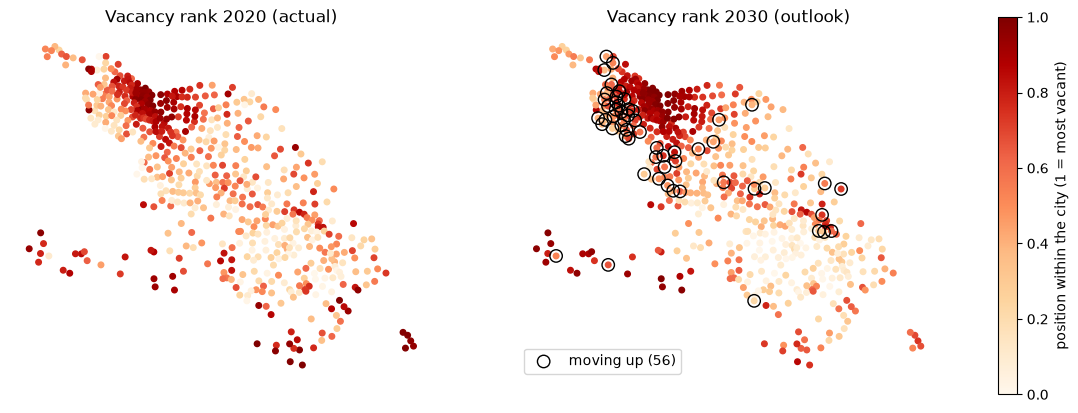

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, col, title in [(ax[0], "rank_2020", "Vacancy rank 2020 (actual)"), (ax[1], "rank_2030_outlook", "Vacancy rank 2030 (outlook)")]:
    s = a.scatter(out.lon, out.lat, c=out[col], cmap="OrRd", s=16, vmin=0, vmax=1)
    a.set_title(title)
    a.set_aspect("equal")
    a.set_axis_off()
up = out[out.outlook == "moving up"]
ax[1].scatter(up.lon, up.lat, s=80, facecolors="none", edgecolors="black", label=f"moving up ({len(up)})")
ax[1].legend(loc="lower left")
fig.colorbar(s, ax=ax, label="position within the city (1 = most vacant)", shrink=0.7)

In [7]:
out.round(3).rename_axis("ageb").to_csv("../results/outlook_2030_ageb.csv")
table.round(3).assign(platform=f"{platform.machine()}, Python {platform.python_version()}").to_csv("../results/outlook_model_selection.csv")
print("saved results/outlook_2030_ageb.csv and results/outlook_model_selection.csv")

saved results/outlook_2030_ageb.csv and results/outlook_model_selection.csv
